# 02 - Temporal analysis

Sampling regularity, autocorrelation, stationarity (ADF / KPSS) and drift for every station. The table produced here is saved as `results/Exploratory_temporal.csv`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd

from config import DATA_PROCESSED, RESULTS_DIR, FIGURES_DIR, SEED

df = pd.read_csv(DATA_PROCESSED / "cleaned_daily.csv", parse_dates=["timestamp"])
print(f"{len(df):,} station-days | {df.station_id.nunique()} stations | "
      f"{df.timestamp.min():%Y-%m-%d} to {df.timestamp.max():%Y-%m-%d}")

40,983 station-days | 95 stations | 2016-11-25 to 2026-04-06


## Per-station coverage

Station series are irregular, so most formal tests are not defined on the full span. Coverage and trend are reported for every station.

In [2]:
from pm25_project.temporal_diagnostics import temporal_table

temporal = temporal_table(df)
pd.Series({
    'stations': len(temporal),
    'station-days': int(temporal.n_records.sum()),
    'median records per station': temporal.n_records.median(),
    'fully regular daily series': int(temporal.acf_lag1.notna().sum()),
    'stations with at least 30 records': int((temporal.n_records >= 30).sum()),
}).to_frame('value')

,value
stations,95.0
station-days,40983.0
median records per station,442.0
fully regular daily series,1.0
stations with at least 30 records,91.0


In [3]:
temporal[['node_id', 'n_records', 'sampling_interval_median_sec', 'pct_days_above_25',
          'trend_slope_per_day', 'cv_strategy_recommended']].head(8).round(3)

,node_id,n_records,sampling_interval_median_sec,pct_days_above_25,trend_slope_per_day,cv_strategy_recommended
0,AIX CENTRE ECOLE ART::43.530285::5.440912,458,86400.0,0.873,0.003,temporal
1,AIX ROY RENE::43.524075::5.448164,198,86400.0,1.515,-0.015,temporal
2,ALBALAT DELS TARONGERS::39.705278::-0.336667,798,86400.0,0.627,-0.001,temporal
3,ALCANTARILLA::37.974500::-1.232100,268,86400.0,4.851,-0.007,temporal
4,ALCORA::40.051944::-0.189722,761,86400.0,1.708,-0.002,temporal
5,ALGAR DE PALÀNCIA::39.782222::-0.359167,771,86400.0,0.519,-0.001,temporal
6,ALMASSORA-C. P. OCHANDO::39.945278::-0.056389,739,86400.0,2.030,-0.002,temporal
7,ALUMBRES::37.602032::-0.914361,197,86400.0,1.015,-0.018,temporal


## Formal diagnostics on uninterrupted segments

ADF, KPSS, Ljung–Box and PACF are only meaningful on gap-free runs. The pipeline cuts each station into contiguous daily segments and tests the ones of at least 30 days; the result is saved as `results/stationarity_acf_development.csv`.

In [4]:
segments = pd.read_csv(RESULTS_DIR / 'stationarity_acf_development.csv')
print(f'{len(segments)} segments across {segments.station_id.nunique()} stations')
print('segments testable with ADF/KPSS:', int(segments.adf_p.notna().sum()))
segments.diagnostics_status.value_counts().to_frame('segments')

73 segments across 73 stations
segments testable with ADF/KPSS: 6


,segments
diagnostics_status,
acf_pacf_only_short_segment,57
no_contiguous_segment_of_14_days,10
ok,6


In [5]:
segments[segments.diagnostics_status.eq('ok')][['station_id', 'segment_start', 'segment_end',
    'n_daily_observations', 'acf_lag1', 'acf_lag7', 'adf_p', 'kpss_p', 'ljung_box_p']].round(4)

,station_id,segment_start,segment_end,n_daily_observations,acf_lag1,acf_lag7,adf_p,kpss_p,ljung_box_p
33,LA ALJORRA::37.693611::-1.064722,2024-06-28T00:00:00+00:00,2024-07-29T00:00:00+00:00,32.0,0.6032,-0.2093,0.0969,0.1,0.0057
38,MEDITERRÁNEO::36.841330::-2.446720,2024-06-28T00:00:00+00:00,2024-07-29T00:00:00+00:00,32.0,-0.0026,-0.0468,0.0000,0.1,0.9463
39,MOLINA DE SEGURA::38.057300::-1.204700,2024-06-29T00:00:00+00:00,2024-07-29T00:00:00+00:00,31.0,0.4447,-0.1016,0.0200,0.1,0.0292
64,VALÈNCIA - MOLÍ DEL SOL::39.481100::-0.408300,2024-06-13T00:00:00+00:00,2024-07-12T00:00:00+00:00,30.0,0.5178,-0.0334,0.1615,0.1,0.1505
65,VALÈNCIA OLIVERETA::39.469220::-0.406050,2024-06-13T00:00:00+00:00,2024-07-12T00:00:00+00:00,30.0,0.5280,-0.0738,0.2310,0.1,0.0652
66,VALÈNCIA-CENTRE::39.448330::-0.376470,2024-06-29T00:00:00+00:00,2024-07-29T00:00:00+00:00,31.0,0.5103,-0.1936,0.3588,0.1,0.0054


## How much memory do the segment series carry?

Lag-1 autocorrelation is close to zero for some stations and above 0.5 for others: persistence is a strong baseline on average, not a uniform one.

63 segments with ACF lag-1; median 0.466, range -0.172 to 0.850


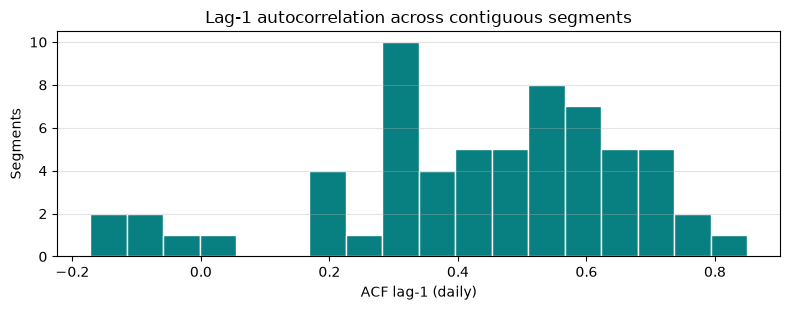

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt

acf = segments.acf_lag1.dropna()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(acf, bins=18, color='#087F80', edgecolor='white')
ax.set(xlabel='ACF lag-1 (daily)', ylabel='Segments', title='Lag-1 autocorrelation across contiguous segments')
ax.grid(axis='y', alpha=0.35)
fig.tight_layout()
print(f'{len(acf)} segments with ACF lag-1; median {acf.median():.3f}, range {acf.min():.3f} to {acf.max():.3f}')

## Monthly pattern and dispersion

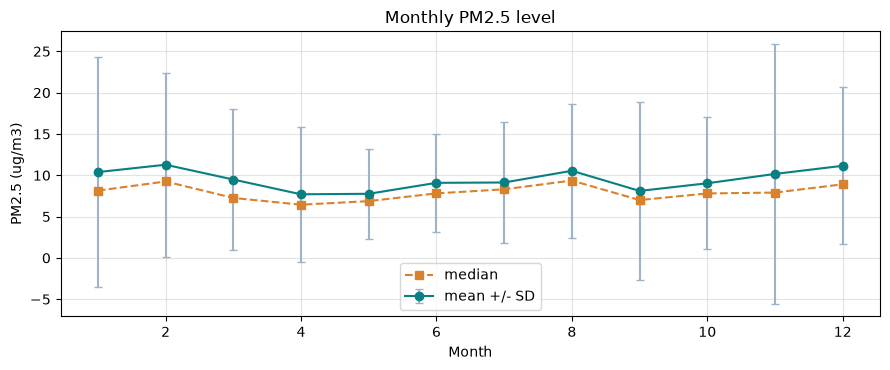

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt

by_month = df.assign(month=df.timestamp.dt.month).groupby('month').pm25.agg(['median', 'mean', 'std'])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.errorbar(by_month.index, by_month['mean'], yerr=by_month['std'], fmt='o-', color='#087F80',
            ecolor='#9FB3C8', capsize=3, label='mean +/- SD')
ax.plot(by_month.index, by_month['median'], 's--', color='#D9822B', label='median')
ax.set(xlabel='Month', ylabel='PM2.5 (ug/m3)', title='Monthly PM2.5 level')
ax.legend()
ax.grid(alpha=0.35)
fig.tight_layout()

## One representative station

Gaps are never bridged when building lags and windows.

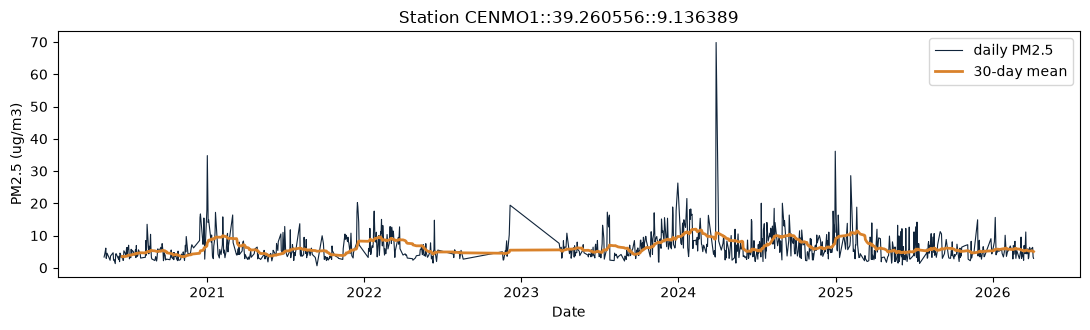

In [8]:
station = temporal.sort_values('n_records', ascending=False).node_id.iloc[0]
series = df[df.station_id.astype(str).eq(str(station))].sort_values('timestamp')
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(series.timestamp, series.pm25, color='#10243A', lw=0.8, label='daily PM2.5')
ax.plot(series.timestamp, series.pm25.rolling(30, min_periods=20).mean(), color='#D9822B', lw=2, label='30-day mean')
ax.set(xlabel='Date', ylabel='PM2.5 (ug/m3)', title=f'Station {station}')
ax.legend()
fig.tight_layout()